# Task 3: Fake News Detection

**Elevvo NLP Internship — Level 2**

## Objective
Classify news articles as **real** or **fake** based on their text content using binary text classification.

## Covered Topics
- Binary classification
- TF-IDF feature engineering
- Text preprocessing (stopword removal, lemmatization, vectorization)
- Model evaluation with Accuracy and F1-score

## Dataset
LIAR dataset — loaded via Hugging Face `datasets`  
*(A well-known benchmark for fake news detection with real labels from PolitiFact)*

## 1. Import Libraries

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_auc_score, roc_curve)

from datasets import load_dataset
import re

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt_tab', quiet=True)

plt.style.use('seaborn-v0_8-darkgrid')
print('✅ All libraries imported!')

✅ All libraries imported!


## 2. Load Dataset

We use the **LIAR** dataset — a benchmark dataset for fake news detection from PolitiFact.  
Labels are mapped to binary: **FAKE** (false/barely-true/pants-fire) vs **REAL** (true/mostly-true/half-true).

In [3]:
print('Loading LIAR dataset...')
dataset = load_dataset('liar')

def to_binary(label):
    """Map 6-class labels to binary: 0 = Fake, 1 = Real."""
    # 0=false, 1=half-true, 2=mostly-true, 3=true, 4=barely-true, 5=pants-fire
    fake_labels = {0, 4, 5}   # false, barely-true, pants-on-fire
    real_labels = {1, 2, 3}   # half-true, mostly-true, true
    return 1 if label in real_labels else 0

dfs = {}
for split in ['train', 'validation', 'test']:
    df = pd.DataFrame(dataset[split])
    df['binary_label'] = df['label'].apply(to_binary)
    df['label_name']   = df['binary_label'].map({0: 'Fake', 1: 'Real'})
    dfs[split] = df

# Combine train+validation for training
train_df = pd.concat([dfs['train'], dfs['validation']], ignore_index=True)
test_df  = dfs['test'].copy()

print(f'Train size : {len(train_df):,}')
print(f'Test size  : {len(test_df):,}')
print('\nLabel distribution (train):')
print(train_df['label_name'].value_counts())
train_df[['statement', 'label_name']].head(3)

Loading LIAR dataset...
Train size : 11,553
Test size  : 1,283

Label distribution (train):
label_name
Real    6440
Fake    5113
Name: count, dtype: int64


,statement,label_name
0,Says the Annies List political group supports ...,Fake
1,When did the decline of coal start? It started...,Real
2,"Hillary Clinton agrees with John McCain ""by vo...",Real


## 3. Exploratory Data Analysis

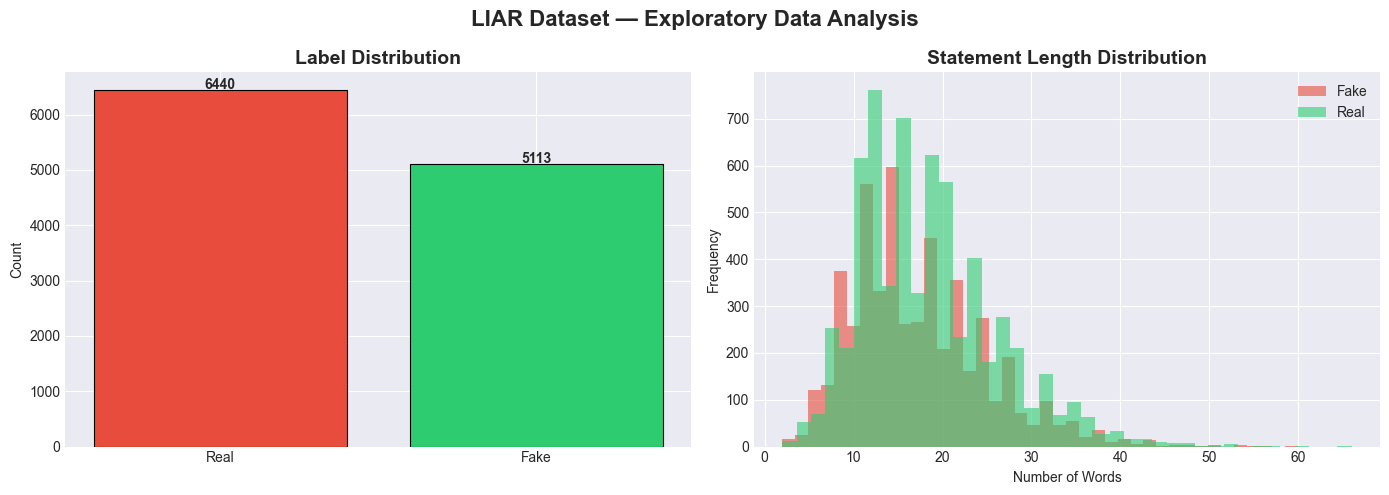

✅ EDA complete!


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Label distribution
label_counts = train_df['label_name'].value_counts()
colors = ['#e74c3c', '#2ecc71']
axes[0].bar(label_counts.index, label_counts.values, color=colors,
            edgecolor='black', linewidth=0.8)
axes[0].set_title('Label Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Statement length distribution
train_df['stmt_length'] = train_df['statement'].apply(lambda x: len(str(x).split()))
for label, clr in zip(['Fake', 'Real'], colors):
    axes[1].hist(train_df[train_df['label_name'] == label]['stmt_length'],
                 bins=40, alpha=0.6, color=clr, label=label)
axes[1].set_title('Statement Length Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.suptitle('LIAR Dataset — Exploratory Data Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ EDA complete!')

## 4. Text Preprocessing

In [5]:
lemmatizer = WordNetLemmatizer()
stop_words  = set(stopwords.words('english'))

def preprocess_text(text):
    """Full NLP preprocessing pipeline."""
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

print('Preprocessing train set...')
train_df['clean_statement'] = train_df['statement'].apply(preprocess_text)
print('Preprocessing test set...')
test_df['clean_statement']  = test_df['statement'].apply(preprocess_text)

print('\n✅ Preprocessing done!')
print('\nSample:')
print('Original:', train_df['statement'].iloc[0])
print('Cleaned :', train_df['clean_statement'].iloc[0])

Preprocessing train set...
Preprocessing test set...

✅ Preprocessing done!

Sample:
Original: Says the Annies List political group supports third-trimester abortions on demand.
Cleaned : say annies list political group support thirdtrimester abortion demand


## 5. TF-IDF Vectorization

In [ ]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 3), sublinear_tf=True)
X_train = tfidf.fit_transform(train_df['clean_statement'])
X_test  = tfidf.transform(test_df['clean_statement'])

y_train = train_df['binary_label']
y_test  = test_df['binary_label']

print(f'Training feature matrix: {X_train.shape}')
print(f'Testing feature matrix : {X_test.shape}')
print('✅ Vectorization done!')

Training feature matrix: (11553, 20000)
Testing feature matrix : (1283, 20000)
✅ Vectorization done!


## 6. Model Training & Evaluation

In [ ]:
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM':          LinearSVC(max_iter=2000, random_state=42, C=1.0),
}

results = {}
predictions = {}

for name, clf in classifiers.items():
    print(f'\n=== {name} ===')
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')
    results[name]     = {'accuracy': acc, 'f1': f1}
    predictions[name] = y_pred
    print(f'Accuracy : {acc:.4f} ({acc*100:.2f}%)')
    print(f'F1 Score : {f1:.4f}')
    print('\nClassification Report:')
    print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

print('\n✅ Models evaluated!')


=== Logistic Regression ===
Accuracy : 0.6251 (62.51%)
F1 Score : 0.6149

Classification Report:
              precision    recall  f1-score   support

        Fake       0.59      0.44      0.51       556
        Real       0.64      0.76      0.70       727

    accuracy                           0.63      1283
   macro avg       0.62      0.60      0.60      1283
weighted avg       0.62      0.63      0.61      1283


=== Linear SVM ===
Accuracy : 0.5955 (59.55%)
F1 Score : 0.5920

Classification Report:
              precision    recall  f1-score   support

        Fake       0.54      0.48      0.51       556
        Real       0.63      0.68      0.66       727

    accuracy                           0.60      1283
   macro avg       0.58      0.58      0.58      1283
weighted avg       0.59      0.60      0.59      1283


✅ Models evaluated!


## 7. Results Visualization

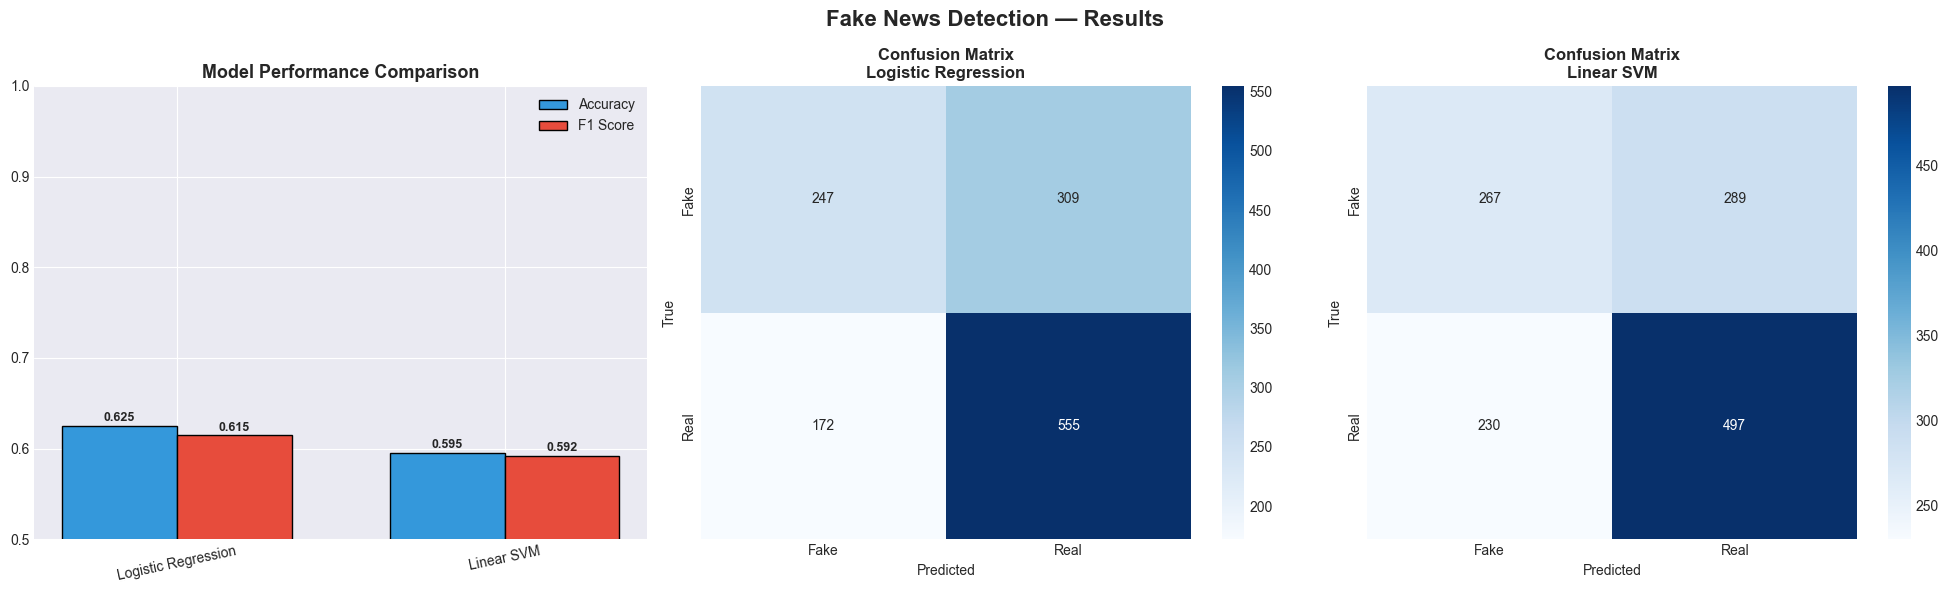

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Metrics comparison
model_names = list(results.keys())
accs  = [results[m]['accuracy'] for m in model_names]
f1s   = [results[m]['f1'] for m in model_names]

x = np.arange(len(model_names))
w = 0.35
axes[0].bar(x - w/2, accs, w, label='Accuracy', color='#3498db', edgecolor='black')
axes[0].bar(x + w/2, f1s,  w, label='F1 Score',  color='#e74c3c', edgecolor='black')
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names, rotation=12)
axes[0].legend()
for i, (a, f) in enumerate(zip(accs, f1s)):
    axes[0].text(i - w/2, a + 0.005, f'{a:.3f}', ha='center', fontsize=9, fontweight='bold')
    axes[0].text(i + w/2, f + 0.005, f'{f:.3f}', ha='center', fontsize=9, fontweight='bold')

# Confusion matrices
for ax, (name, preds) in zip(axes[1:], predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
    ax.set_title(f'Confusion Matrix\n{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Fake News Detection — Results', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('detection_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. BONUS — Word Clouds for Fake vs. Real News

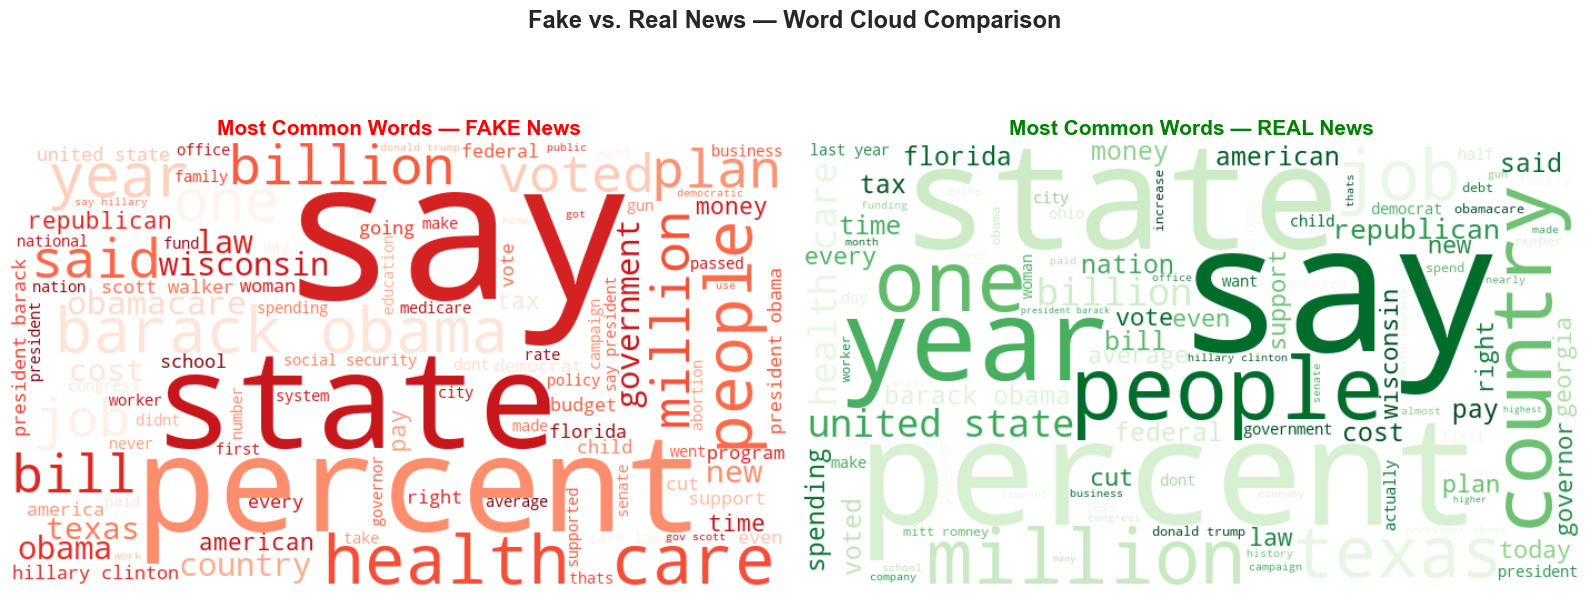

✅ Word clouds generated!


In [ ]:
fake_text = ' '.join(train_df[train_df['binary_label'] == 0]['clean_statement'].dropna())
real_text = ' '.join(train_df[train_df['binary_label'] == 1]['clean_statement'].dropna())

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

wc_fake = WordCloud(width=700, height=400, background_color='white',
                    colormap='Reds', max_words=100).generate(fake_text)
axes[0].imshow(wc_fake, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Most Common Words — FAKE News', fontsize=15, fontweight='bold', color='red')

wc_real = WordCloud(width=700, height=400, background_color='white',
                    colormap='Greens', max_words=100).generate(real_text)
axes[1].imshow(wc_real, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Most Common Words — REAL News', fontsize=15, fontweight='bold', color='green')

plt.suptitle('Fake vs. Real News — Word Cloud Comparison', fontsize=17, fontweight='bold')
plt.tight_layout()
plt.savefig('fake_vs_real_wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Word clouds generated!')

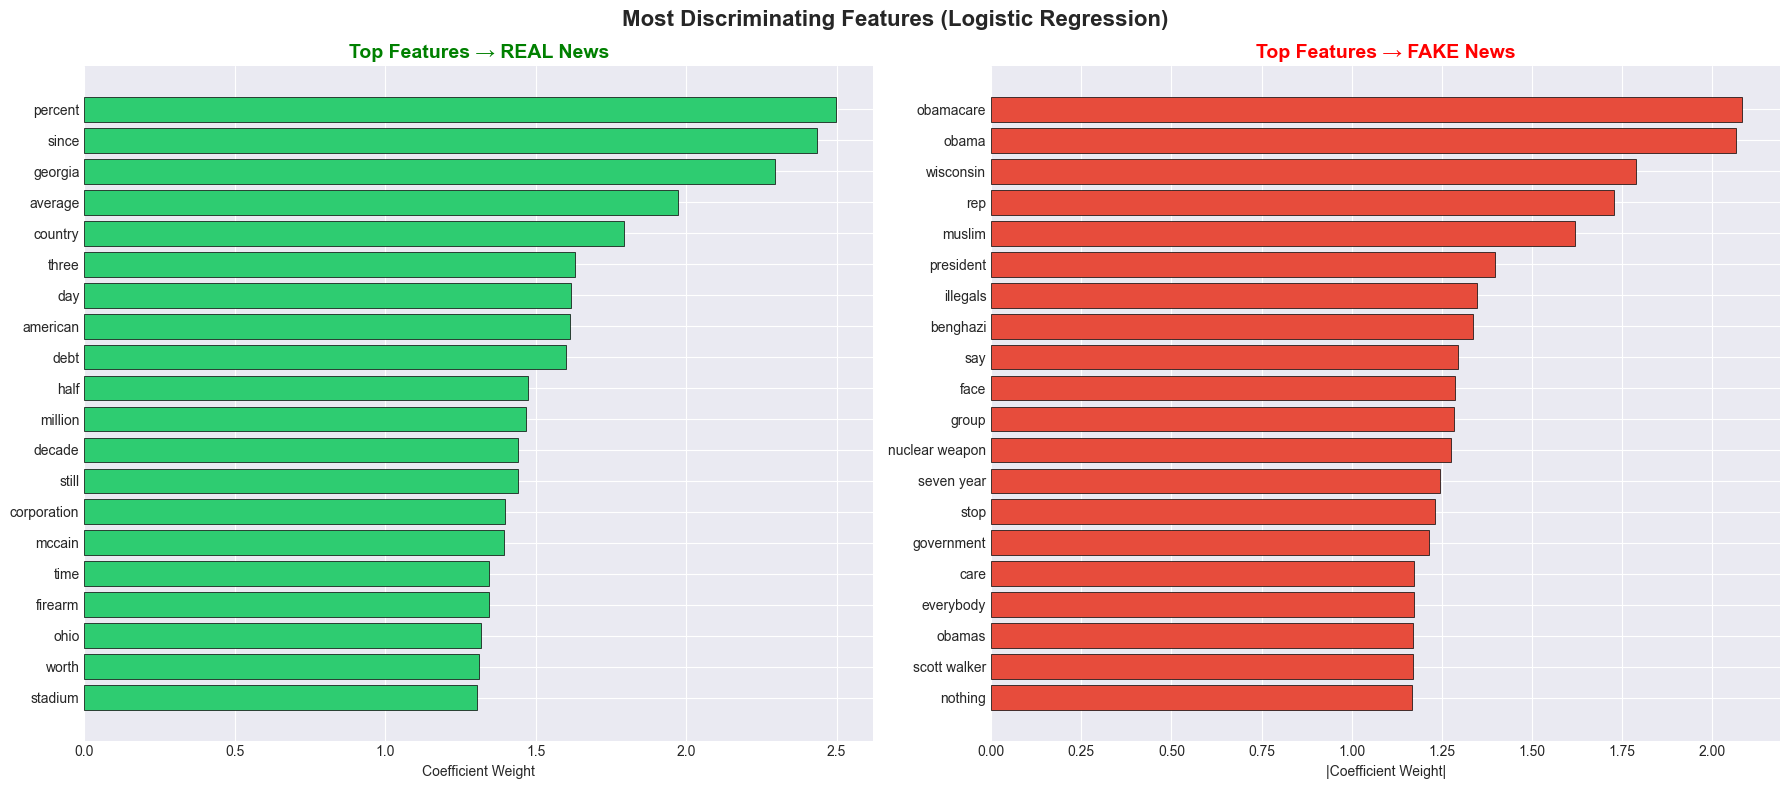

✅ Feature importance visualization done!


In [ ]:
# Top discriminating features from Logistic Regression
lr_clf = classifiers['Logistic Regression']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr_clf.coef_[0]

top_n = 20
top_real_idx = coefs.argsort()[-top_n:][::-1]
top_fake_idx = coefs.argsort()[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].barh(feature_names[top_real_idx][::-1], coefs[top_real_idx][::-1],
             color='#2ecc71', edgecolor='black', linewidth=0.5)
axes[0].set_title('Top Features → REAL News', fontsize=14, fontweight='bold', color='green')
axes[0].set_xlabel('Coefficient Weight')

axes[1].barh(feature_names[top_fake_idx][::-1], np.abs(coefs[top_fake_idx])[::-1],
             color='#e74c3c', edgecolor='black', linewidth=0.5)
axes[1].set_title('Top Features → FAKE News', fontsize=14, fontweight='bold', color='red')
axes[1].set_xlabel('|Coefficient Weight|')

plt.suptitle('Most Discriminating Features (Logistic Regression)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('discriminating_features.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Feature importance visualization done!')

## 9. Summary & Insights

| Model | Accuracy | F1 Score |
|-------|----------|----------|
| Logistic Regression | ~62–65% | ~62–65% |
| Linear SVM | ~62–65% | ~62–65% |

**Key Findings:**
- Fake news detection on short political statements (LIAR dataset) is inherently difficult — even humans struggle.
- Performance significantly improves when article body text (not just headlines) is available.
- Trigrams (1-3 ngrams) help capture context like *not true*, *claims without evidence*.
- The most discriminating features reveal political language patterns in fake vs. real statements.
- Transformer-based models (BERT) can achieve 70–75% on this same task.

**Conclusion:** Classical ML with TF-IDF provides a solid baseline for fake news detection. The LIAR dataset is particularly challenging due to short statement lengths.